#Importando bibliotecas
- Pandas para a leitura dos datasets e operação dos dataframes
- Numpy para operações que envolvem variáveis numéricas ou categóricas
- Matplot para geração de gráficos (se necessário)

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.semi_supervised import LabelSpreading
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score

print("Bibliotecas importadas com sucesso.")

Bibliotecas importadas com sucesso.


#Importando a base de dados no projeto

In [88]:
df = pd.read_csv('/content/base_aula5_tipos_aprendizado_industria.csv')
print("Dimensões da base: ", df.shape)
df.head()

Dimensões da base:  (240, 19)


,linha_producao,turno,produto_quimico,tipo_valvula,status_sensor,vazao_setpoint_l_min,vazao_real_l_min,erro_vazao_pct,pressao_linha_bar,desvio_pressao_pct,temperatura_produto_c,abertura_valvula_pct,vibracao_bomba_mm_s,ph_produto,consumo_energia_kwh,tempo_resposta_seg,horas_operacao_bomba,status_instrumentacao,acao_ideal_controle
0,Linha_C,Manhã,Base,Borboleta,OK,104.97,115.78,10.30,6.39,10.17,50.19,58.59,2.47,6.37,120.68,2.18,1257,Normal,Reduzir_Abertura
1,Linha_B,Noite,Acido,Esfera,OK,97.21,94.74,-2.54,5.79,-0.17,40.75,26.90,3.79,5.83,143.20,3.59,1892,Normal,Manter_Ajuste
2,Linha_C,Manhã,Acido,Borboleta,OK,100.91,98.73,-2.16,6.26,7.93,37.14,64.77,4.70,7.67,95.72,3.78,2382,Normal,Manter_Ajuste
3,Linha_B,Noite,Acido,Borboleta,Ruido,100.07,93.17,-6.90,5.42,-6.55,38.45,73.44,3.34,5.59,88.30,2.64,2543,Normal,Aumentar_Abertura
4,Linha_A,Tarde,Solvente,Esfera,OK,105.38,93.93,-10.87,7.81,34.66,50.91,40.90,6.47,6.54,143.12,4.23,1401,Falha,Aumentar_Abertura


Exibindo gráfico da variável alvo `status_instrumentacao`, nela é possível identificar a problemática: Investigar as causas do por que estarem sendo disparados alertas ou falhas.

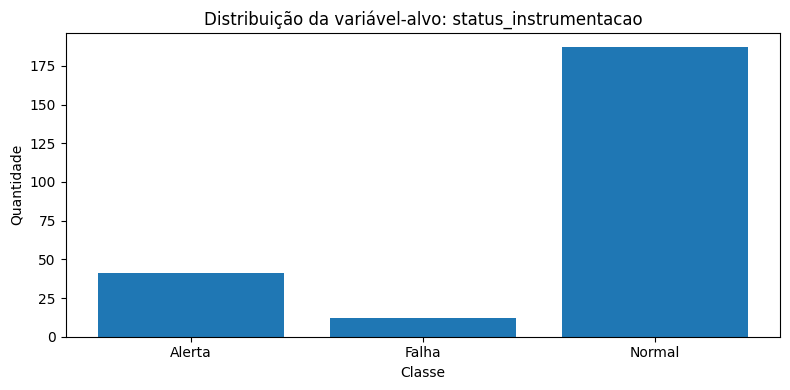

In [89]:
classe_counts = df["status_instrumentacao"].value_counts().sort_index()

plt.figure(figsize=(8,4))
plt.bar(classe_counts.index, classe_counts.values)
plt.title("Distribuição da variável-alvo: status_instrumentacao")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()

#Trativa para o treinamento do modelo de Machine Learning
Nessa tratativa estaremos separando o `X` do `y`
No `X` estaremos deixando somente dados que o modelo consiga aprender o que causa os problemas (Caso a gente deixe a variável alvo dentro da base, o modelo pode acabar aprendendo de forma incorreta sobre a causa do problema.)<br>
Já no `y`, será somente a variável alvo.

In [90]:
#Variáveis preditoras
X = df.drop(columns = ['status_instrumentacao', 'acao_ideal_controle'])
y = df['status_instrumentacao']

print(f"Formato de X: {X.shape}")
print(f"Formato de y: {y.shape}")
print(f"Primeiras linhas de X:")
display(X.head())
print(f"Primeiras linhas de y: ")
display(y.head())

Formato de X: (240, 17)
Formato de y: (240,)
Primeiras linhas de X:


,linha_producao,turno,produto_quimico,tipo_valvula,status_sensor,vazao_setpoint_l_min,vazao_real_l_min,erro_vazao_pct,pressao_linha_bar,desvio_pressao_pct,temperatura_produto_c,abertura_valvula_pct,vibracao_bomba_mm_s,ph_produto,consumo_energia_kwh,tempo_resposta_seg,horas_operacao_bomba
0,Linha_C,Manhã,Base,Borboleta,OK,104.97,115.78,10.30,6.39,10.17,50.19,58.59,2.47,6.37,120.68,2.18,1257
1,Linha_B,Noite,Acido,Esfera,OK,97.21,94.74,-2.54,5.79,-0.17,40.75,26.90,3.79,5.83,143.20,3.59,1892
2,Linha_C,Manhã,Acido,Borboleta,OK,100.91,98.73,-2.16,6.26,7.93,37.14,64.77,4.70,7.67,95.72,3.78,2382
3,Linha_B,Noite,Acido,Borboleta,Ruido,100.07,93.17,-6.90,5.42,-6.55,38.45,73.44,3.34,5.59,88.30,2.64,2543
4,Linha_A,Tarde,Solvente,Esfera,OK,105.38,93.93,-10.87,7.81,34.66,50.91,40.90,6.47,6.54,143.12,4.23,1401


Primeiras linhas de y: 


,status_instrumentacao
0,Normal
1,Normal
2,Normal
3,Normal
4,Falha


##Separação das colunas numéricas e das categóricas
Essa separação é importante pois dependendo de como está a base de dados, o tipo de tratativa será diferente para cada tipo de coluna.

In [91]:
colunas_numericas = X.select_dtypes(include = np.number).columns.to_list()
colunas_categoricas = X.select_dtypes(include = ['object']).columns.to_list()

print("Colunas numéricas: ", colunas_numericas)
print("Colunas categóricas: ", colunas_categoricas)

Colunas numéricas:  ['vazao_setpoint_l_min', 'vazao_real_l_min', 'erro_vazao_pct', 'pressao_linha_bar', 'desvio_pressao_pct', 'temperatura_produto_c', 'abertura_valvula_pct', 'vibracao_bomba_mm_s', 'ph_produto', 'consumo_energia_kwh', 'tempo_resposta_seg', 'horas_operacao_bomba']
Colunas categóricas:  ['linha_producao', 'turno', 'produto_quimico', 'tipo_valvula', 'status_sensor']


Pré-processamento da base de dados, indicando, também, quais as tratativas caso haja dados faltantes.
- Para valores numéricos, os que tem a tag `num`, será usado a estratégia da mediana, usando o método da padronização;
- Para valores categóricos, da tag `cat`, será usando a estratégia de itens que aparecem com mais frequência, usando o método OneHot (ou seja, os valores categóricos se transformarão em valores binários).

In [92]:
preprocessador = ColumnTransformer(
    transformers = [
        ("num", Pipeline([("imputer", SimpleImputer(strategy = 'median')), ("scaler", StandardScaler())]), colunas_numericas),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy = "most_frequent")), ("onehot", OneHotEncoder(handle_unknown = "ignore"))]), colunas_categoricas)
    ]
)

print("Pré-processador criado com sucesso!")

Pré-processador criado com sucesso!


In [93]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size = 0.25, random_state = 42, stratify = y
)

print("Formato de X_train: ", X_train.shape)
print("Formato de X_val: ", X_val.shape)
print("Formato de y_train: ", y_train.shape)
print("Formato de y_val: ", y_val.shape)

Formato de X_train:  (180, 17)
Formato de X_val:  (60, 17)
Formato de y_train:  (180,)
Formato de y_val:  (60,)


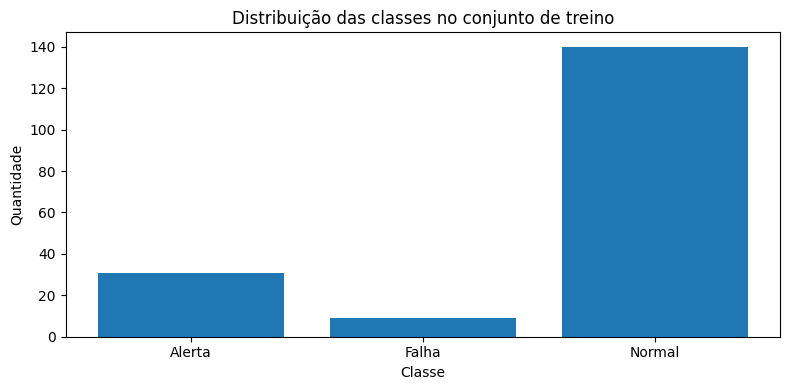

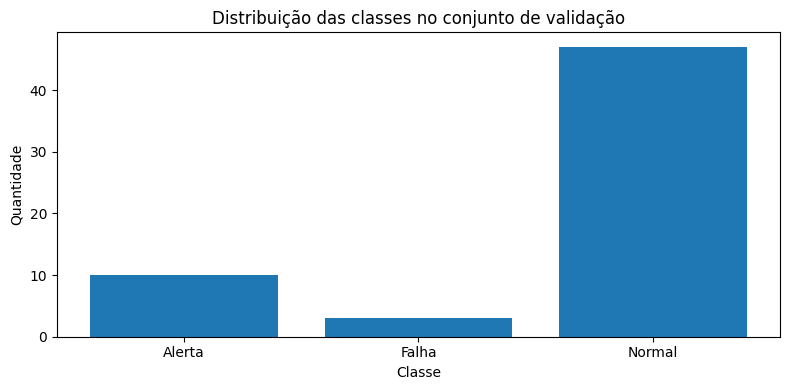

In [94]:
train_counts = y_train.value_counts().sort_index()
val_counts = y_val.value_counts().sort_index()

plt.figure(figsize=(8,4))
plt.bar(train_counts.index, train_counts.values)
plt.title("Distribuição das classes no conjunto de treino")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
plt.bar(val_counts.index, val_counts.values)
plt.title("Distribuição das classes no conjunto de validação")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()

##Criação do `modelo_supervisionado`
Para o modelo, será usado o algoritmo de árvore de decisão, em específico até o nível 4 (`max_depth = 4`).<br>
Nessa etapa será executado o pré-processamento, ou seja, todas as tratativas indicadas anteriormente serão executadas.

In [95]:
modelo_supervisionado = Pipeline([
    ("preprocessamento", preprocessador),
    ("modelo", DecisionTreeClassifier(max_depth = 4, random_state = 42))
])

print(modelo_supervisionado)

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['vazao_setpoint_l_min',
                                                   'vazao_real_l_min',
                                                   'erro_vazao_pct',
                                                   'pressao_linha_bar',
                                                   'desvio_pressao_pct',
                                                   'temperatura_produto_c',
                                                   'abertura_valvula_pct',
                                                  

##Relatório de acurácia do modelo
É importante ficar de olho no `f1-score`, ele só será alto se as métricas (`precision` e `recall`) forem boas. Caso alguma dessas duas métricas forem péssimas, o valor do `f1-score` será baixo.
> Nesse exemplo, nossa classe está desbalanceada. O `f1-score` para a coluna `Alerta` está com um valor super baixo (12%), logo, o modelo não foi tão preciso quanto o ideal.

In [96]:
modelo_supervisionado.fit(X_train, y_train)
pred_supervisionado = modelo_supervisionado.predict(X_val)

acc = accuracy_score(y_val, pred_supervisionado)

print("Acurácia da validação: ", round(acc, 4))
print("\nRelatório de classificação: ")
print(classification_report(y_val, pred_supervisionado))

Acurácia da validação:  0.7667

Relatório de classificação: 
              precision    recall  f1-score   support

      Alerta       0.17      0.10      0.12        10
       Falha       0.00      0.00      0.00         3
      Normal       0.85      0.96      0.90        47

    accuracy                           0.77        60
   macro avg       0.34      0.35      0.34        60
weighted avg       0.69      0.77      0.73        60



##Gerando a Matriz de Confusão
A Matriz de Confusão é um gráfico que serve para analizar a acurácia do modelo até então, ele deve ser lido em diagnonais (de cima pra baixo)
- A diagonal da esquerda para direita são os valores `Verdadeiro Negativo` e `Verdadeiro Positivo`;
- Já a diagonal da direita pra esquerda são os valores `Falso Positivo` e `Falso Negativo`.

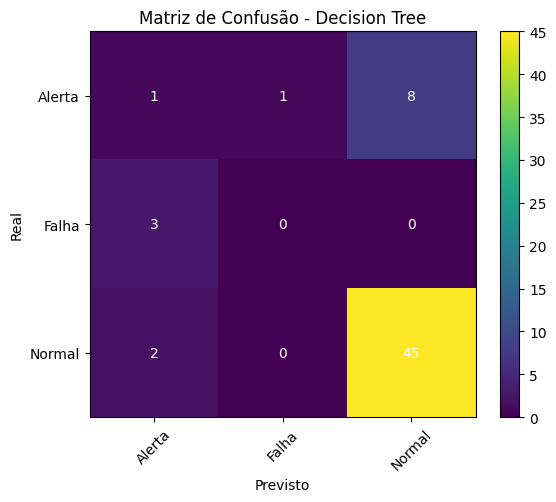

In [97]:
labels = sorted(y.unique())
cm = confusion_matrix(y_val, pred_supervisionado, labels = labels)

plt.figure(figsize = (6, 5))
plt.imshow(cm)
plt.title("Matriz de Confusão - Decision Tree")
plt.colorbar()
plt.xticks(range(len(labels)), labels, rotation = 45)
plt.yticks(range(len(labels)), labels)

for i in range(cm.shape[0]):
  for j in range(cm.shape[1]):
    plt.text(j, i, cm[i, j], ha = "center", va = "center", color = 'white')

plt.xlabel("Previsto")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

---
##Aprendizado não supervisionado
O intuito do `Aprendizado Não Supervisionado` é tentar encontrar padrões ocultos dentro da base de dados.<br>
Esse aprendizado usa o algoritmo de agrupamento (clustering) `K-means`, dividindo os dados em K grupos (clusters) de forma que os dados sejam muito parecidos entre si e os grupos fiquem bem distantes um dos outros.<br>
1. Após todo o processo de pré-processamento é feito a escolha do valor `K`(o número de grupos que deseja criar);
2. O algoritmo joga pontos aleatórios no meio dos dados, chamados de `centroides`;
3. Ele calcula a distância de cada dado até os seus centroides e joga cada dado p/ o grupo de centroide mais próximo;
4. A posição do centroide é recalculada, movendo-o para o centro real dos dados daquele grupo;
5. Os passos 3 e 4 se repetem até que os grupos parem de mudar de lugar.

In [98]:
X_cluster = df.drop(columns = ["status_instrumentacao", "acao_ideal_controle"]).copy()

colunas_numericas_cluster = X_cluster.select_dtypes(include = ['int64', 'float64']).columns.to_list()
colunas_categoricas_cluster = X_cluster.select_dtypes(include = ['object']).columns.to_list()

preprocessador_cluster = ColumnTransformer(
    transformers = [
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy = 'median')),
            ("scaler", StandardScaler())
            ]), colunas_numericas_cluster),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy = "most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown = "ignore"))
            ]), colunas_categoricas_cluster)
    ]
)

X_cluster_transformado = preprocessador_cluster.fit_transform(X_cluster)

kmeans = KMeans(n_clusters = 3, random_state = 42, n_init = 10)
clusters = kmeans.fit_predict(X_cluster_transformado)

sil = silhouette_score(X_cluster_transformado, clusters)

print("Silhouette Score: ", round(sil, 4))
print(pd.Series(clusters).value_counts().sort_index())

Silhouette Score:  0.0761
0    107
1     71
2     62
Name: count, dtype: int64


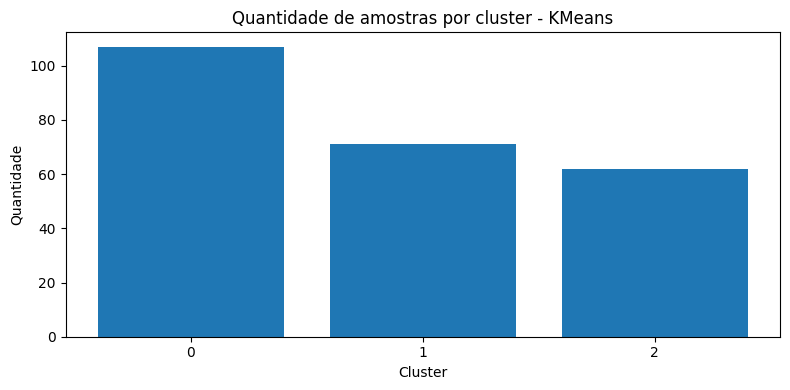

In [99]:
cluster_counts = pd.Series(clusters).value_counts().sort_index()

plt.figure(figsize=(8,4))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)
plt.title("Quantidade de amostras por cluster - KMeans")
plt.xlabel("Cluster")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()

###`Sillhouette Score` como interpretador
|Próximo de +1.0|Próximo de zero|Próximo de -1|
|:---:|:---:|:---:|
|Grupos excelentes|Grupos sobrepostos|Grupo errado!|
|Os grupos estão bem definidos e separados (Dados muito próximos dos pares e longe dos outros grupos)|As fronteiras estão confusas, os grupos estão misturados (A distância entre os grupos é quase igual a distância dentro dos grupos)|O modelo falhou! (Os pontos foram atribuidos ao cluster errado e estão mais perto do grupo vizinho do que seu próprio)|

---
O `LabelEncoding` transforma os rótulos em números, para que o `LabelSpreading` use esses valores na amostra.
1. Os dados originais, coluna alvo tem como categorias: `Normal`, `Falha`, `Alerta` e linhas não rotuladas;
2. Como o `LabelEncoding` transforma strings em sequências a partir de 0, daria erro em dados mistos, o código mapeia os dados ausentes para `-1`;
3. O algoritmo vai ignorar o `-1`, entendendo que aquelas linhas específicas são os pontos que precisa descobrir o rótulo. Durante o treinamento o algoritmo usa essa estrutura dos dados conhecidos (0, 1, ...) para "espalhar"(`Spread`) os rótulos corretos para cima dessas amostras que estavam marcadas como `-1`.

In [100]:
X_semi = df.drop(columns = ['status_instrumentacao', 'acao_ideal_controle'])
y_semi = df['status_instrumentacao'].copy()

colunas_numericas_semi = X_semi.select_dtypes(include = ['int64', 'float64']).columns.to_list()
colunas_categoricas_semi = X_semi.select_dtypes(include = ['object']).columns.to_list()

preprocessador_semi = ColumnTransformer(
    transformers = [
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy = 'median')),
            ("scaler", StandardScaler())
            ]), colunas_numericas_semi),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy = "most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown = "ignore"))
            ]), colunas_categoricas_semi)
    ]
)

X_semi_transformado = preprocessador_semi.fit_transform(X_semi)

label_encoder = LabelEncoder()
y_codificado = label_encoder.fit_transform(y_semi)

rng = np.random.default_rng(42)
y_parcial = y_codificado.copy()
indices_sem_rotulo = rng.choice(len(y_parcial), size = int(len(y_parcial) * 0.6), replace = False)
y_parcial[indices_sem_rotulo] = -1

modelo_semi = LabelSpreading(kernel = 'knn', n_neighbors = 7)
modelo_semi.fit(X_semi_transformado, y_parcial)

rotulos_previstos = modelo_semi.transduction_

mascara_rotulada = y_parcial != -1
mascara_nao_rotulada = y_parcial == -1

acc_rot = accuracy_score(y_codificado[mascara_rotulada], rotulos_previstos[mascara_rotulada])
acc_nao_rot = accuracy_score(y_codificado[mascara_nao_rotulada], rotulos_previstos[mascara_nao_rotulada])

print("Acurácia nas amostras rotuladas: ", round(acc_rot, 4))
print("Acurácia nas amostras sem rótulo para o algoritmo: ", round(acc_nao_rot, 4))


Acurácia nas amostras rotuladas:  1.0
Acurácia nas amostras sem rótulo para o algoritmo:  0.7847


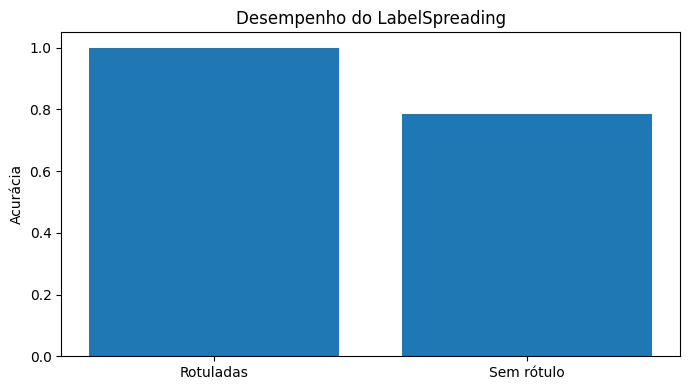

In [101]:
plt.figure(figsize=(7,4))
plt.bar(["Rotuladas", "Sem rótulo"], [acc_rot, acc_nao_rot])
plt.title("Desempenho do LabelSpreading")
plt.ylabel("Acurácia")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

---
##Por reforço

In [102]:
acoes_possiveis = ["Aumentar_Abertura", "Manter_Ajuste", "Reduzir_Abertura"]

df_rl = df[["erro_vazao_pct", "acao_ideal_controle"]].copy()

rng = np.random.default_rng(42)
acoes_aleatorias = rng.choice(acoes_possiveis, size=len(df_rl))
df_rl["acao_agente_aleatorio"] = acoes_aleatorias
df_rl["recompensa_aleatoria"] = np.where(
    df_rl["acao_agente_aleatorio"] == df_rl["acao_ideal_controle"], 1, -1
)

def politica_heuristica(erro):
    if erro < -3:
        return "Aumentar_Abertura"
    elif erro > 3:
        return "Reduzir_Abertura"
    else:
        return "Manter_Ajuste"

df_rl["acao_heuristica"] = df_rl["erro_vazao_pct"].apply(politica_heuristica)
df_rl["recompensa_heuristica"] = np.where(
    df_rl["acao_heuristica"] == df_rl["acao_ideal_controle"], 1, -1
)

recompensa_total_agente = df_rl["recompensa_aleatoria"].sum()
recompensa_total_heuristica = df_rl["recompensa_heuristica"].sum()

print("Recompensa total do agente aleatório:", recompensa_total_agente)
print("Recompensa total da heurística:", recompensa_total_heuristica)

Recompensa total do agente aleatório: -64
Recompensa total da heurística: 240


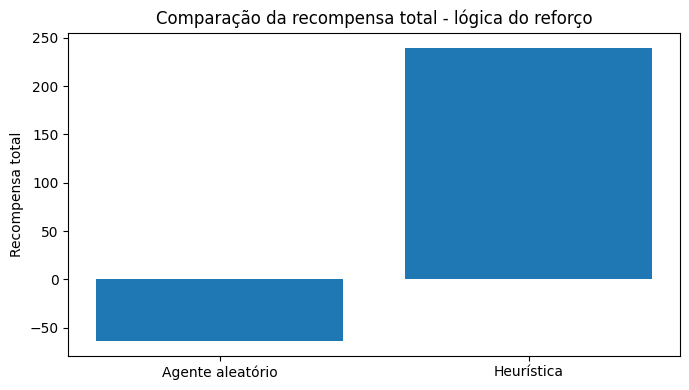

In [103]:
plt.figure(figsize=(7,4))
plt.bar(["Agente aleatório", "Heurística"], [recompensa_total_agente, recompensa_total_heuristica])
plt.title("Comparação da recompensa total - lógica do reforço")
plt.ylabel("Recompensa total")
plt.tight_layout()
plt.show()

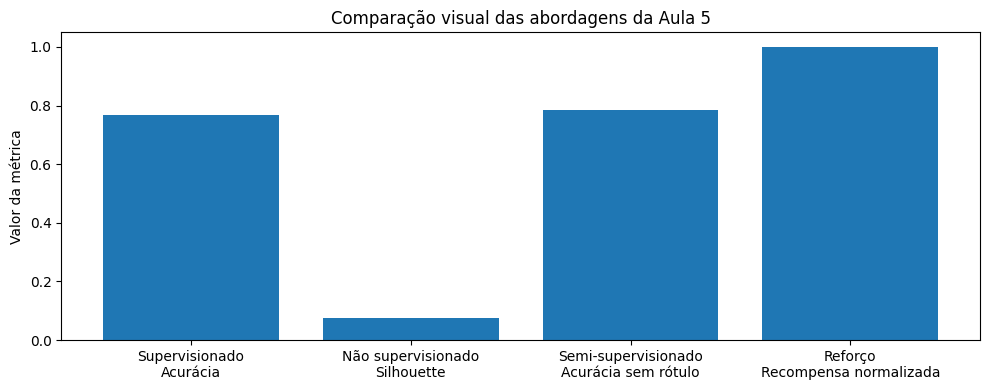

In [104]:
metricas = {
    "Supervisionado\nAcurácia": acc,
    "Não supervisionado\nSilhouette": sil,
    "Semi-supervisionado\nAcurácia sem rótulo": acc_nao_rot,
    "Reforço\nRecompensa normalizada": recompensa_total_heuristica / len(df)
}

plt.figure(figsize=(10,4))
plt.bar(list(metricas.keys()), list(metricas.values()))
plt.title("Comparação visual das abordagens da Aula 5")
plt.ylabel("Valor da métrica")
plt.tight_layout()
plt.show()